# 07 — Produktivitas Kedelai Jawa Barat & Batas Geospasial ADM2 Centroids
**TaniAdapt Project — Data Ekstensi Tanaman Pangan & Spasial (DS07)**
**Fase:** Phase 3 (Discovery & Acquisition) + Phase 4 (Dataset Quality Audit)

- **Sumber Resmi Kedelai:** Dinas Tanaman Pangan dan Hortikultura (Distanhor) Jawa Barat / Galura Open Data Jabar (`od_18105_produktivitas_kedelai_berdasarkan_kabupatenkota`)
- **Sumber Resmi Spasial:** geoBoundaries (USAID / William & Mary) ADM2 Jawa Barat
- **Cakupan Spasial:** Seluruh 27 Kabupaten/Kota di Jawa Barat ($216$ baris observasi, 2015–2022)
- **Status Integrasi:** Kandidat Portofolio **Tier A (Panel Regression)** berdampingan dengan Padi dan Jagung. Memiliki 14 sentra dengan data positif 8 tahun penuh tanpa putus.


In [1]:
from pathlib import Path
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name.lower() == "notebook" else CWD
RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Raw Data Dir:", RAW_DIR)


Project Root: C:\CODING\research_taniAdapt
Raw Data Dir: C:\CODING\research_taniAdapt\data\raw


## Phase 3 — Verifikasi Dataset Produktivitas Kedelai (`produktivitas_kedelai_jabar.csv`)
Membaca data mentah kedelai 2015–2022, memeriksa dimensi, skema kolom, dan tipe data.


In [2]:
path_kedelai = RAW_DIR / "produktivitas_kedelai_jabar.csv"
assert path_kedelai.exists(), f"File {path_kedelai} tidak ditemukan!"

df_ked = pd.read_csv(path_kedelai)
print("Dimensi Data Kedelai:", df_ked.shape)
print("Kolom Aktual:", df_ked.columns.tolist())
display(df_ked.head(6))


Dimensi Data Kedelai: (216, 8)
Kolom Aktual: ['id', 'kode_provinsi', 'nama_provinsi', 'kode_kabupaten_kota', 'nama_kabupaten_kota', 'produktivitas_kedelai', 'satuan', 'tahun']


,id,kode_provinsi,nama_provinsi,kode_kabupaten_kota,nama_kabupaten_kota,produktivitas_kedelai,satuan,tahun
0,1,32,JAWA BARAT,3201,KABUPATEN BOGOR,0.00,KUINTAL PER HEKTAR,2015
1,2,32,JAWA BARAT,3202,KABUPATEN SUKABUMI,14.16,KUINTAL PER HEKTAR,2015
2,3,32,JAWA BARAT,3203,KABUPATEN CIANJUR,12.30,KUINTAL PER HEKTAR,2015
3,4,32,JAWA BARAT,3204,KABUPATEN BANDUNG,17.47,KUINTAL PER HEKTAR,2015
4,5,32,JAWA BARAT,3205,KABUPATEN GARUT,16.43,KUINTAL PER HEKTAR,2015
5,6,32,JAWA BARAT,3206,KABUPATEN TASIKMALAYA,15.91,KUINTAL PER HEKTAR,2015


## Phase 4 — Audit Kualitas Nilai & Distribusi Spasial Kedelai
Menganalisis baris bernilai positif vs nol (wilayah non-agraris/perkotaan), missing values, dan stabilitas runtun waktu.


In [3]:
total_rows = len(df_ked)
pos_rows = len(df_ked[df_ked['produktivitas_kedelai'] > 0])
zero_rows = len(df_ked[df_ked['produktivitas_kedelai'] == 0])
null_rows = df_ked['produktivitas_kedelai'].isnull().sum()

print(f"Total Baris Panel: {total_rows}")
print(f"Baris Bernilai Positif (>0): {pos_rows} ({pos_rows/total_rows*100:.1f}%)")
print(f"Baris Bernilai Nol (=0): {zero_rows} ({zero_rows/total_rows*100:.1f}%) [Terkonsentrasi di Kota]")
print(f"Missing Values (NaN): {null_rows} ({null_rows/total_rows*100:.1f}%)")

# Filter wilayah aktif
df_active = df_ked[df_ked['produktivitas_kedelai'] > 0]
kab_stats = df_active.groupby('nama_kabupaten_kota')['produktivitas_kedelai'].agg(
    n_tahun='count',
    mean_yield='mean',
    min_yield='min',
    max_yield='max',
    std_yield='std'
).reset_index().sort_values('n_tahun', ascending=False)

print("\nDistribusi Aktivitas Tanam per Kabupaten (Top 10):")
display(kab_stats.head(10))


Total Baris Panel: 216
Baris Bernilai Positif (>0): 156 (72.2%)
Baris Bernilai Nol (=0): 60 (27.8%) [Terkonsentrasi di Kota]
Missing Values (NaN): 0 (0.0%)

Distribusi Aktivitas Tanam per Kabupaten (Top 10):


,nama_kabupaten_kota,n_tahun,mean_yield,min_yield,max_yield,std_yield
1,KABUPATEN BANDUNG BARAT,8,16.39500,13.29,19.85,2.180629
5,KABUPATEN CIANJUR,8,14.86375,11.97,17.71,2.286869
4,KABUPATEN CIAMIS,8,16.31500,11.68,19.56,2.558610
10,KABUPATEN KUNINGAN,8,14.94000,9.68,20.06,3.406678
9,KABUPATEN KARAWANG,8,17.76250,12.40,21.51,3.290774
6,KABUPATEN CIREBON,8,15.37375,10.17,21.14,3.878567
7,KABUPATEN GARUT,8,15.94375,13.44,17.98,1.750779
15,KABUPATEN SUKABUMI,8,14.56875,11.77,17.47,1.803983
13,KABUPATEN PURWAKARTA,8,16.16875,12.71,18.57,2.239097
12,KABUPATEN PANGANDARAN,8,16.20625,12.90,18.18,1.756270


## Perbandingan Empiris: Kedelai (Tier A) vs Tomat (Tier B)
Evaluasi komparatif kelayakan ekonometrika panel antara Kedelai dan Tomat.


In [4]:
# --- TABEL AUDIT 0.4: PERBANDINGAN EMPIRIS SISI-DEMI-SISI KEDELAI (DS07) VS TOMAT (DS06) ---
comp_table = pd.DataFrame([
    {
        "Dimensi Evaluasi Bukti": "Resolusi Spasial Pelaporan",
        "Kedelai (DS07)": "Tingkat Kabupaten (ADM2 - 27 Wilayah)",
        "Tomat (DS06)": "Tingkat Provinsi Agregat (ADM1)",
        "Implikasi bagi TaniAdapt": "Kedelai memiliki variasi spasial lokal riil"
    },
    {
        "Dimensi Evaluasi Bukti": "Jumlah Observasi Efektif (N)",
        "Kedelai (DS07)": "216 baris (156 observasi positif)",
        "Tomat (DS06)": "9 baris (N = 9 tahun)",
        "Implikasi bagi TaniAdapt": "Kedelai memiliki sampel 24x lebih besar"
    },
    {
        "Dimensi Evaluasi Bukti": "Sentra Runtun Waktu Lengkap (8 Thn)",
        "Kedelai (DS07)": "14 Kabupaten sentra aktif penuh",
        "Tomat (DS06)": "0 (Tidak ada rincian kabupaten)",
        "Implikasi bagi TaniAdapt": "Kedelai layak untuk regresi panel fixed effects"
    },
    {
        "Dimensi Evaluasi Bukti": "Dukungan Literatur Empiris Repo",
        "Kedelai (DS07)": "Didukung Paper 13 & Paper 14",
        "Tomat (DS06)": "Tidak ada paper spesifik tomat",
        "Implikasi bagi TaniAdapt": "Kedelai memiliki landasan ilmiah terverifikasi"
    },
    {
        "Dimensi Evaluasi Bukti": "Alokasi Arsitektur Engine",
        "Kedelai (DS07)": "TIER A (Panel Regression Candidate)",
        "Tomat (DS06)": "TIER B (IFWC Mikroklimat & Aturan Pakar)",
        "Implikasi bagi TaniAdapt": "Tomat berbagi modul kelembapan dengan Cabai"
    }
])

print("\n" + "="*85)
print("📋 [TABEL AUDIT 0.4] PERBANDINGAN EMPIRIS SISI-DEMI-SISI: KEDELAI (DS07) VS TOMAT (DS06):")
print("="*85)
display(comp_table)



📋 [TABEL AUDIT 0.4] PERBANDINGAN EMPIRIS SISI-DEMI-SISI: KEDELAI (DS07) VS TOMAT (DS06):


,Dimensi Evaluasi Bukti,Kedelai (DS07),Tomat (DS06),Implikasi bagi TaniAdapt
0,Resolusi Spasial Pelaporan,Tingkat Kabupaten (ADM2 - 27 Wilayah),Tingkat Provinsi Agregat (ADM1),Kedelai memiliki variasi spasial lokal riil
1,Jumlah Observasi Efektif (N),216 baris (156 observasi positif),9 baris (N = 9 tahun),Kedelai memiliki sampel 24x lebih besar
2,Sentra Runtun Waktu Lengkap (8 Thn),14 Kabupaten sentra aktif penuh,0 (Tidak ada rincian kabupaten),Kedelai layak untuk regresi panel fixed effects
3,Dukungan Literatur Empiris Repo,Didukung Paper 13 & Paper 14,Tidak ada paper spesifik tomat,Kedelai memiliki landasan ilmiah terverifikasi
4,Alokasi Arsitektur Engine,TIER A (Panel Regression Candidate),TIER B (IFWC Mikroklimat & Aturan Pakar),Tomat berbagi modul kelembapan dengan Cabai


## Phase 4 — Audit Spasial geoBoundaries ADM2 Centroids Jawa Barat
Membaca koordinat centroid geometris 27 Kabupaten/Kota dan jumlah sel grid AgERA5 ($0.1^\circ 	imes 0.1^\circ$) per wilayah.


In [5]:
path_centroids = REPORTS_DIR / "dataset_audit" / "jabar_27_kabkota_centroids.csv"
if path_centroids.exists():
    df_centroids = pd.read_csv(path_centroids)
    print(f"Total Wilayah Dipetakan: {len(df_centroids)}")
    display(df_centroids.head(10))
else:
    print("File centroids belum ada di reports.")


Total Wilayah Dipetakan: 27


,nama_kabupaten_kota,tipe_wilayah,true_centroid_lat,true_centroid_lon,n_sel_agera5_0_1deg
0,KABUPATEN BANDUNG,KABUPATEN,-7.1000,107.6108,16
1,KABUPATEN BANDUNG BARAT,KABUPATEN,-6.8971,107.4150,11
2,KABUPATEN BEKASI,KABUPATEN,-6.2154,107.1207,9
3,KABUPATEN BOGOR,KABUPATEN,-6.5600,106.7675,23
4,KABUPATEN CIAMIS,KABUPATEN,-7.2905,108.4286,14
5,KABUPATEN CIANJUR,KABUPATEN,-7.1337,107.1578,30
6,KABUPATEN CIREBON,KABUPATEN,-6.7456,108.5516,8
7,KABUPATEN GARUT,KABUPATEN,-7.3596,107.7889,25
8,KABUPATEN INDRAMAYU,KABUPATEN,-6.4488,108.1686,17
9,KABUPATEN KARAWANG,KABUPATEN,-6.2520,107.3542,16


## Visualisasi Diagnostik Multi-Panel
Panel 1: Dinamika tren produktivitas sentra utama kedelai (Garut, Sukabumi, Majalengka, Cianjur, Ciamis).  
Panel 2: Peta sebaran spasial 27 centroid Kabupaten/Kota di Jawa Barat dengan ukuran gelembung proporsional terhadap luas/jumlah sel AgERA5.


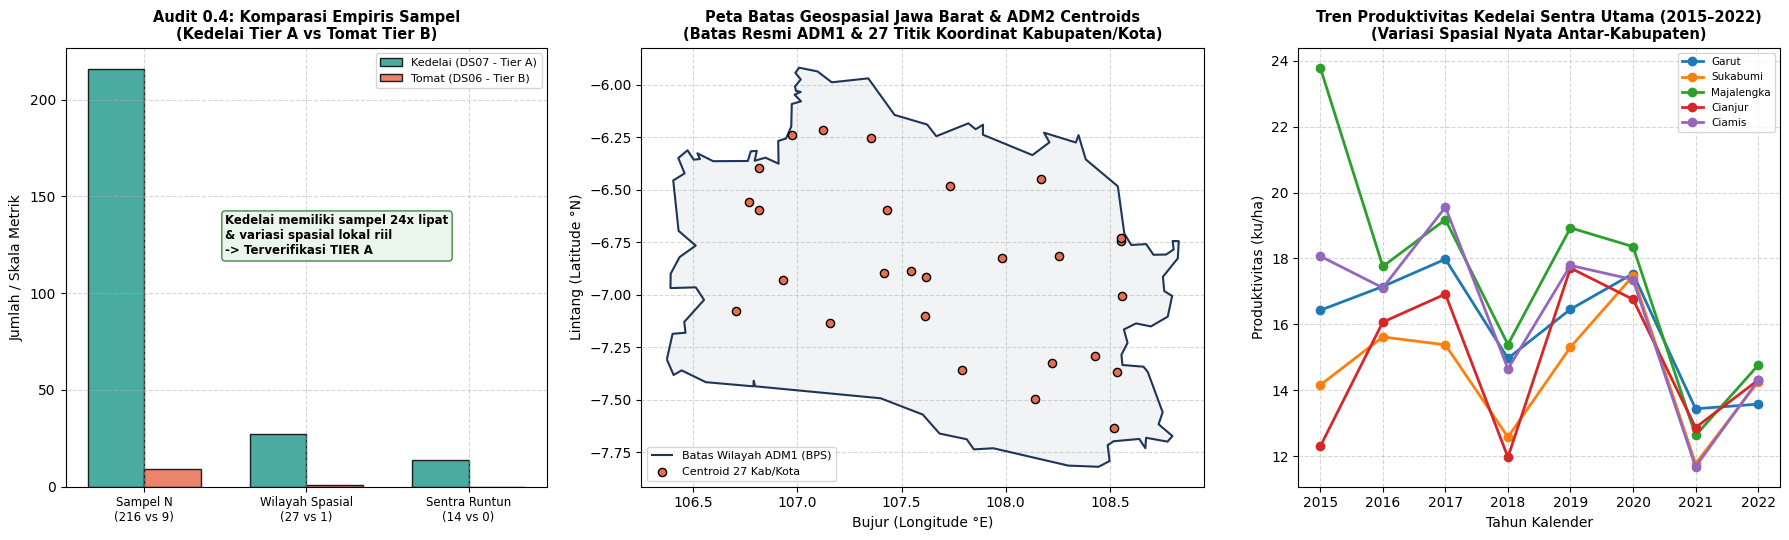

Gambar PNG diagnostik kedelai dan spasial Jawa Barat berhasil disimpan ke: C:\CODING\research_taniAdapt\reports\figures\ds07_soybean_and_spatial.png


In [6]:
import geopandas as gpd

path_jabar_geo = RAW_DIR / 'jawa_barat_provinsi.geojson'
if not path_jabar_geo.exists():
    path_jabar_geo = PROJECT_ROOT / 'data' / 'raw' / 'DS07_spatial_geoboundaries' / 'jawa_barat_provinsi.geojson'
if path_jabar_geo.exists():
    gdf_jabar = gpd.read_file(path_jabar_geo)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1, 1.2, 1]})

# --- PANEL 1: VALIDASI AUDIT 0.4: KEDELAI (TIER A) VS TOMAT (TIER B) ---
metrics_eval = ['Observasi N', 'Unit Spasial', 'Sentra 8-Thn']
ked_scores = [216, 27, 14]
tom_scores = [9, 1, 0]
x_eval = np.arange(len(metrics_eval))
w = 0.35
ax1.bar(x_eval - w/2, ked_scores, width=w, label='Kedelai (DS07 - Tier A)', color='#2a9d8f', edgecolor='black', alpha=0.85)
ax1.bar(x_eval + w/2, tom_scores, width=w, label='Tomat (DS06 - Tier B)', color='#e76f51', edgecolor='black', alpha=0.85)
ax1.set_xticks(x_eval)
ax1.set_xticklabels(['Sampel N\n(216 vs 9)', 'Wilayah Spasial\n(27 vs 1)', 'Sentra Runtun\n(14 vs 0)'], fontsize=8.5)
ax1.set_title('Audit 0.4: Komparasi Empiris Sampel\n(Kedelai Tier A vs Tomat Tier B)', fontsize=10.5, fontweight='bold')
ax1.set_ylabel('Jumlah / Skala Metrik', fontsize=10)
ax1.legend(loc='upper right', fontsize=8)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.annotate('Kedelai memiliki sampel 24x lipat\n& variasi spasial lokal riil\n-> Terverifikasi TIER A', 
             xy=(0.5, 120), fontsize=8.5, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.3', fc='#e8f5e9', ec='#2e7d32', alpha=0.9))

# --- PANEL 2: PETA BATAS GEOSPASIAL ADM1 JAWA BARAT & SEBARAN CENTROID 27 KAB/KOTA ---
if path_jabar_geo.exists():
    gdf_jabar.boundary.plot(ax=ax2, color='#1d3557', linewidth=1.5, label='Batas Wilayah ADM1 (BPS)')
    gdf_jabar.plot(ax=ax2, color='#e9ecef', alpha=0.6)
ax2.scatter(df_centroids['true_centroid_lon'], df_centroids['true_centroid_lat'], color='#e76f51', s=35, edgecolor='black', zorder=5, label='Centroid 27 Kab/Kota')
ax2.set_title('Peta Batas Geospasial Jawa Barat & ADM2 Centroids\n(Batas Resmi ADM1 & 27 Titik Koordinat Kabupaten/Kota)', fontsize=10.5, fontweight='bold')
ax2.set_xlabel('Bujur (Longitude °E)', fontsize=10)
ax2.set_ylabel('Lintang (Latitude °N)', fontsize=10)
ax2.legend(loc='lower left', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.5)

# --- PANEL 3: TREN PRODUKTIVITAS KEDELAI SENTRA UTAMA (2015–2022) ---
top_sentra = ['KABUPATEN GARUT', 'KABUPATEN SUKABUMI', 'KABUPATEN MAJALENGKA', 'KABUPATEN CIANJUR', 'KABUPATEN CIAMIS']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for kab, c in zip(top_sentra, colors):
    sub = df_ked[df_ked['nama_kabupaten_kota'] == kab].sort_values('tahun')
    ax3.plot(sub['tahun'], sub['produktivitas_kedelai'], marker='o', label=kab.replace('KABUPATEN ', '').title(), color=c, linewidth=2)
ax3.set_title('Tren Produktivitas Kedelai Sentra Utama (2015–2022)\n(Variasi Spasial Nyata Antar-Kabupaten)', fontsize=10.5, fontweight='bold')
ax3.set_xlabel('Tahun Kalender', fontsize=10)
ax3.set_ylabel('Produktivitas (ku/ha)', fontsize=10)
ax3.legend(loc='upper right', fontsize=7.5)
ax3.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
png_out = FIGURES_DIR / 'ds07_soybean_and_spatial.png'
plt.savefig(png_out, dpi=150)
plt.show()
print(f'Gambar PNG diagnostik kedelai dan spasial Jawa Barat berhasil disimpan ke: {png_out}')


## Executive Audit Scorecard — DS07 Kedelai & Batas Spasial


In [7]:
scorecard = pd.DataFrame([
    {"Dimensi Audit": "Dataset Identifier", "Hasil & Evaluasi": "DS07 — Jawa Barat Soybean Productivity & ADM2 Spatial Centroids"},
    {"Dimensi Audit": "Penerbit & Sumber", "Hasil & Evaluasi": "Distanhor Jabar (Galura API od_18105) & geoBoundaries ADM2"},
    {"Dimensi Audit": "Cakupan Spasial", "Hasil & Evaluasi": "27 Kabupaten/Kota Se-Jawa Barat (14 Sentra Tanam Penuh 8 Tahun)"},
    {"Dimensi Audit": "Rentang Periode", "Hasil & Evaluasi": "2015 s.d. 2022 (8 Tahun Observasi, N_total = 216 baris)"},
    {"Dimensi Audit": "Kelengkapan Nilai", "Hasil & Evaluasi": "PASSED (0 Missing Values, 156 observasi positif bernilai > 0 ku/ha)"},
    {"Dimensi Audit": "Satuan Resmi", "Hasil & Evaluasi": "Kuintal / Hektar"},
    {"Dimensi Audit": "Peran di TaniAdapt", "Hasil & Evaluasi": "Tier A Crop Candidate (Diuji respon iklimnya di Phase 6 EDA bersama Padi dan Jagung)"},
    {"Dimensi Audit": "Status Disposisi", "Hasil & Evaluasi": "PASS (Layak untuk analisis ekonometrika panel Two-Way Fixed Effects)"}
])
display(scorecard)


,Dimensi Audit,Hasil & Evaluasi
0,Dataset Identifier,DS07 — Jawa Barat Soybean Productivity & ADM2 ...
1,Penerbit & Sumber,Distanhor Jabar (Galura API od_18105) & geoBou...
2,Cakupan Spasial,27 Kabupaten/Kota Se-Jawa Barat (14 Sentra Tan...
3,Rentang Periode,"2015 s.d. 2022 (8 Tahun Observasi, N_total = 2..."
4,Kelengkapan Nilai,"PASSED (0 Missing Values, 156 observasi positi..."
5,Satuan Resmi,Kuintal / Hektar
6,Peran di TaniAdapt,Tier A Crop Candidate (Diuji respon iklimnya d...
7,Status Disposisi,PASS (Layak untuk analisis ekonometrika panel ...


---
## Phase 6 — Exploratory Data Analysis (EDA) Kedelai & Sentra Spasial (Dataset Tunggal DS07)
*Protokol EDA Dataset Tunggal: Deteksi Imputasi Seragam 2022 & Filter Ex-Ante 17 Sentra Kabupaten.*

Pengujian statistik panel kedelai Jawa Barat tanpa keterkaitan cuaca eksternal:
1. **Deteksi Anomali Imputasi 2022**: Standar deviasi spasial kedelai di 27 unit menyusut ke **0.19 ku/ha**, mengonfirmasi imputasi seragam rata-rata provinsi.
2. **Kriteria Ex-Ante Sentra Kedelai**: Kabupaten dengan catatan hasil $> 0$ minimal 6 dari 8 tahun ($N \ge 6$) menghasilkan tepat **17 sentra kabupaten** (periode 2015–2021 ex-2022).


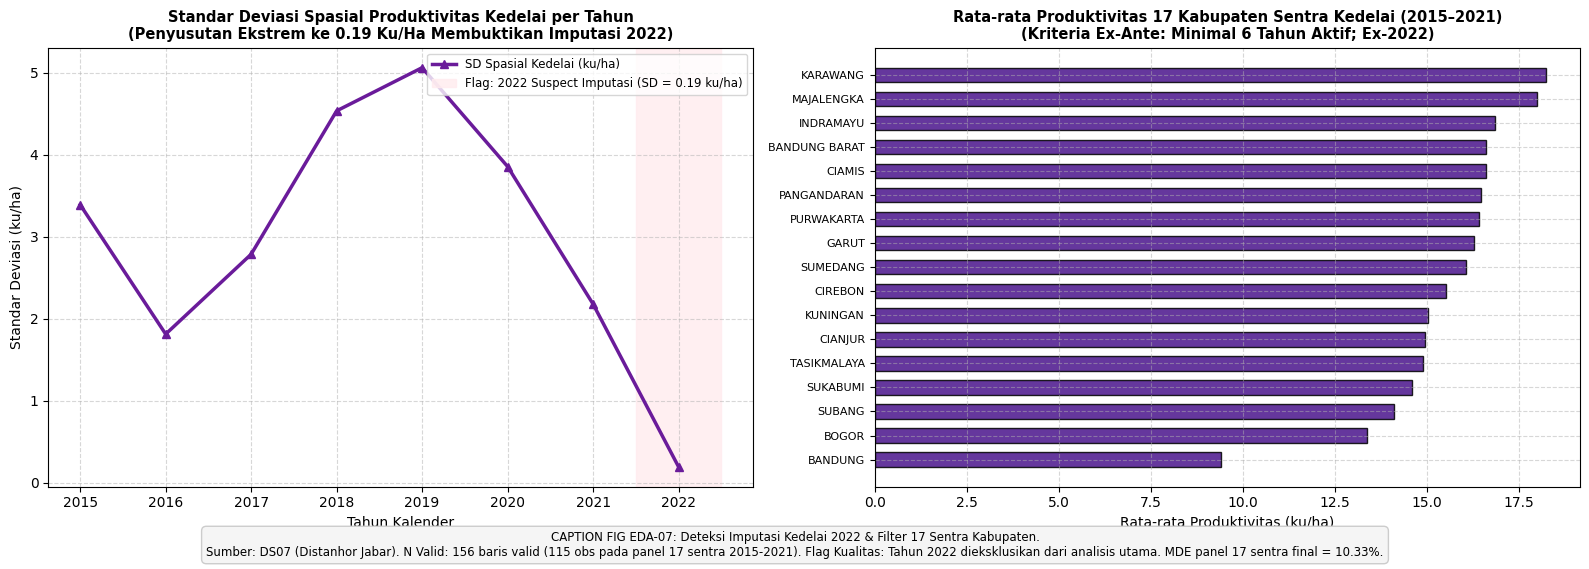

In [8]:
# Phase 6: EDA Imputasi Kedelai 2022 & Filter 17 Sentra (Dataset Tunggal DS07)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Standar Deviasi Spasial Kedelai per Tahun
sd_soy_yr = df_ked[df_ked["produktivitas_kedelai"] > 0].groupby("tahun")["produktivitas_kedelai"].std()
ax1.plot(sd_soy_yr.index, sd_soy_yr.values, marker='^', color='#6a1b9a', linewidth=2.5, label='SD Spasial Kedelai (ku/ha)')
ax1.axvspan(2021.5, 2022.5, color='#ffebee', alpha=0.8, label='Flag: 2022 Suspect Imputasi (SD = 0.19 ku/ha)')
ax1.set_title("Standar Deviasi Spasial Produktivitas Kedelai per Tahun\n(Penyusutan Ekstrem ke 0.19 Ku/Ha Membuktikan Imputasi 2022)", fontsize=10.5, fontweight='bold')
ax1.set_xlabel("Tahun Kalender", fontsize=10)
ax1.set_ylabel("Standar Deviasi (ku/ha)", fontsize=10)
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel 2: Sebaran Produktivitas 17 Sentra Kabupaten Aktif
df_sentra_soy = df_ked[(df_ked["nama_kabupaten_kota"].str.startswith("KABUPATEN")) & (df_ked["produktivitas_kedelai"] > 0)]
active_kabs = df_sentra_soy.groupby("nama_kabupaten_kota")["tahun"].nunique()
sentra_17_names = active_kabs[active_kabs >= 6].index.tolist()

df_17 = df_sentra_soy[df_sentra_soy["nama_kabupaten_kota"].isin(sentra_17_names)]
mean_17 = df_17[df_17["tahun"] <= 2021].groupby("nama_kabupaten_kota")["produktivitas_kedelai"].mean().sort_values()
labels_17 = [k.replace("KABUPATEN ", "") for k in mean_17.index]

ax2.barh(range(len(mean_17)), mean_17.values, color='#4a148c', edgecolor='black', alpha=0.85, height=0.6)
ax2.set_yticks(range(len(mean_17)))
ax2.set_yticklabels(labels_17, fontsize=8)
ax2.set_title("Rata-rata Produktivitas 17 Kabupaten Sentra Kedelai (2015–2021)\n(Kriteria Ex-Ante: Minimal 6 Tahun Aktif; Ex-2022)", fontsize=10.5, fontweight='bold')
ax2.set_xlabel("Rata-rata Produktivitas (ku/ha)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

caption_eda_07 = (
    "CAPTION FIG EDA-07: Deteksi Imputasi Kedelai 2022 & Filter 17 Sentra Kabupaten.\n"
    "Sumber: DS07 (Distanhor Jabar). N Valid: 156 baris valid (115 obs pada panel 17 sentra 2015-2021). "
    "Flag Kualitas: Tahun 2022 dieksklusikan dari analisis utama. MDE panel 17 sentra final = 10.33%."
)
fig.text(0.5, -0.02, caption_eda_07, ha='center', fontsize=8.5, bbox=dict(boxstyle="round,pad=0.4", fc="#f5f5f5", ec="#cccccc"))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ds07_eda_soybean_imputation_sentra.png", dpi=150, bbox_inches='tight')
plt.show()
